# Credit Scoring — Análise de Sustentação e Confiabilidade

Notebook de apoio visual ao Tech Challenge Fase 4. **Não é um entregável
obrigatório do enunciado** — a validação de dados, a detecção de drift e a
observabilidade já estão implementadas em `src/` e documentadas em `docs/`.
Este notebook existe para tornar essa análise **inspecionável visualmente**,
num só lugar, sem precisar ler módulo por módulo.

Tudo aqui é leitura de artefatos já gerados por `make pipeline` — o notebook
não re-treina nada nem reprocessa dado. Se os gráficos parecerem desatualizados,
rode `make pipeline` e reexecute as células.

**Roteiro:**

1. [EDA do dataset bruto](#1) — os problemas reais que justificam o contrato
2. [Da limpeza ao contrato](#2) — antes/depois, auditável
3. [O modelo baseline](#3) — LogReg vs. XGBoost
4. [Os cinco lotes de drift](#4) — PSI, distribuições, AUC
5. [O achado: degradação silenciosa](#5) — o lote que engana o PSI
6. [Atribuição causal](#6) — quanto é data drift, quanto é concept drift
7. [Conclusões](#7)

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

sys.path.insert(0, "..")

from src.config.settings import FEATURES, TARGET, settings
from src.contracts.schemas import CreditReferenceSchema
from src.contracts.validate import validate_batch
from src.credit_scoring.dataset import clean
from src.credit_scoring.metrics import compute_metrics
from src.credit_scoring.train import load_model, score
from src.drift.simulate import SCENARIOS
from src.drift.statistics import drift_table, dataset_drift_summary

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

# Paleta do projeto (mesma do dashboard HTML e do Grafana) — mantém os
# gráficos deste notebook visualmente consistentes com os outros relatórios.
BLUE = "#2a78d6"
BLUE_LIGHT = "#86b6ef"
GOOD = "#0ca30c"
WARNING = "#fab219"
SERIOUS = "#ec835a"
CRITICAL = "#d03b3b"
GRAY = "#898781"
GRID = "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
})

ROOT = Path("..")

/root/credit-scoring-observability/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/10/19 11:47:40 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /root/credit-scoring-observability/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


<a id="1"></a>
## 1. EDA do dataset bruto

Dataset: [Give Me Some Credit](https://www.kaggle.com/c/GiveMeSomeCredit)
(Kaggle), 150.000 propostas de crédito, alvo binário `SeriousDlqin2yrs`
(inadimplência grave em 2 anos). Baixado e salvo em `data/raw/credit.csv` por
`src/credit_scoring/dataset.py::download_raw`.

A pergunta desta seção não é "como o modelo se sai" — é **"por que o contrato
de dados tem exatamente estas dez regras?"**. A resposta está nos defeitos do
próprio dado.

In [2]:
raw = pd.read_csv(ROOT / "data" / "raw" / "credit.csv")
print(f"shape: {raw.shape[0]:,} linhas x {raw.shape[1]} colunas".replace(",", "."))
raw.head()

shape: 150.000 linhas x 11 colunas


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [3]:
resumo = pd.DataFrame({
    "nulos": raw.isna().sum(),
    "% nulos": (raw.isna().mean() * 100).round(2),
    "min": raw.min(numeric_only=True),
    "max": raw.max(numeric_only=True),
}).join(raw.describe().T[["mean", "50%"]].rename(columns={"50%": "mediana"}))
resumo

,nulos,% nulos,min,max,mean,mediana
SeriousDlqin2yrs,0,0.00,0.0,1.0,0.066840,0.000000
RevolvingUtilizationOfUnsecuredLines,0,0.00,0.0,50708.0,6.048438,0.154181
age,0,0.00,0.0,109.0,52.295207,52.000000
NumberOfTime30-59DaysPastDueNotWorse,0,0.00,0.0,98.0,0.421033,0.000000
DebtRatio,0,0.00,0.0,329664.0,353.005076,0.366508
MonthlyIncome,29731,19.82,0.0,3008750.0,6670.221237,5400.000000
NumberOfOpenCreditLinesAndLoans,0,0.00,0.0,58.0,8.452760,8.000000
NumberOfTimes90DaysLate,0,0.00,0.0,98.0,0.265973,0.000000
NumberRealEstateLoansOrLines,0,0.00,0.0,54.0,1.018240,1.000000
NumberOfTime60-89DaysPastDueNotWorse,0,0.00,0.0,98.0,0.240387,0.000000


Quatro problemas saltam aos olhos — e cada um vira uma regra específica em
`src/contracts/schemas.py`:

| Observado acima | Regra do contrato |
|---|---|
| `MonthlyIncome`: 19,8% nulo | `not_nullable` |
| `age`: mínimo = 0 | `age >= 18` |
| `DebtRatio`: máximo = 329.664 | `DebtRatio <= 10.0` |
| `RevolvingUtilizationOfUnsecuredLines`: máximo = 50.708 | `<= 10.0` (é uma proporção) |

Os gráficos abaixo tornam isso visível.

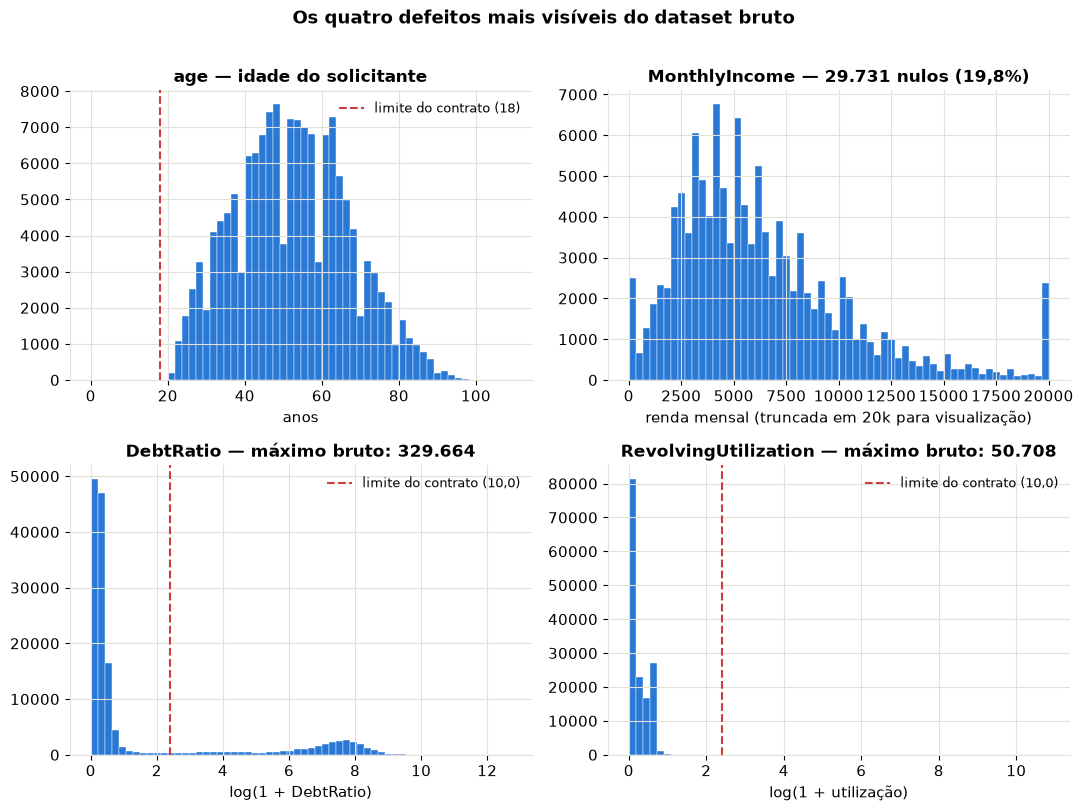

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

# Idade: cauda à esquerda em zero (impossível) — eixo em escala normal.
ax = axes[0, 0]
ax.hist(raw["age"], bins=60, color=BLUE, edgecolor="white", linewidth=0.3)
ax.axvline(18, color=CRITICAL, linestyle="--", linewidth=1.5, label="limite do contrato (18)")
ax.set_title("age — idade do solicitante")
ax.set_xlabel("anos")
ax.legend(frameon=False, fontsize=9)

# Renda: nulos marcados explicitamente como categoria própria.
ax = axes[0, 1]
renda_valida = raw["MonthlyIncome"].dropna()
n_nulos = raw["MonthlyIncome"].isna().sum()
ax.hist(renda_valida.clip(upper=20000), bins=60, color=BLUE, edgecolor="white", linewidth=0.3)
n_nulos_fmt = f"{n_nulos:,}".replace(",", ".")
pct_nulos_fmt = f"{n_nulos / len(raw) * 100:.1f}".replace(".", ",")
ax.set_title(f"MonthlyIncome — {n_nulos_fmt} nulos ({pct_nulos_fmt}%)")
ax.set_xlabel("renda mensal (truncada em 20k para visualização)")

# DebtRatio: escala log por causa da cauda absurda.
ax = axes[1, 0]
ax.hist(np.log1p(raw["DebtRatio"]), bins=60, color=BLUE, edgecolor="white", linewidth=0.3)
ax.axvline(np.log1p(10), color=CRITICAL, linestyle="--", linewidth=1.5, label="limite do contrato (10,0)")
ax.set_title(f"DebtRatio — máximo bruto: {raw['DebtRatio'].max():,.0f}".replace(",", "."))
ax.set_xlabel("log(1 + DebtRatio)")
ax.legend(frameon=False, fontsize=9)

# RevolvingUtilization: idem.
ax = axes[1, 1]
ax.hist(np.log1p(raw["RevolvingUtilizationOfUnsecuredLines"]), bins=60, color=BLUE,
        edgecolor="white", linewidth=0.3)
ax.axvline(np.log1p(10), color=CRITICAL, linestyle="--", linewidth=1.5, label="limite do contrato (10,0)")
ax.set_title(f"RevolvingUtilization — máximo bruto: {raw['RevolvingUtilizationOfUnsecuredLines'].max():,.0f}".replace(",", "."))
ax.set_xlabel("log(1 + utilização)")
ax.legend(frameon=False, fontsize=9)

fig.suptitle("Os quatro defeitos mais visíveis do dataset bruto", fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()

In [5]:
# Os contadores de atraso usam 96/98 como código de sistema legado
# ("sem histórico avaliável"), não como quantidade real de ocorrências.
colunas_atraso = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
]
sentinela = raw[colunas_atraso].isin([96, 98]).any(axis=1).sum()
duplicatas = raw.duplicated().sum()

print(f"Linhas com sentinela 96/98 em algum contador de atraso: {sentinela:,}".replace(",", "."))
print(f"Linhas duplicadas: {duplicatas:,}".replace(",", "."))
print()
print("Distribuição de NumberOfTimes90DaysLate (valores mais frequentes):")
raw["NumberOfTimes90DaysLate"].value_counts().head(8)

Linhas com sentinela 96/98 em algum contador de atraso: 269
Linhas duplicadas: 609

Distribuição de NumberOfTimes90DaysLate (valores mais frequentes):


NumberOfTimes90DaysLate
0     141662
1       5243
2       1555
3        667
4        291
98       264
5        131
6         80
Name: count, dtype: int64

> Os valores 96 e 98 aparecem com frequência suspeita para "contagem real de
> atrasos" — é a assinatura clássica de um código de sistema legado vazando
> como número. Daí a regra `<= 20` nos três contadores.

**Validando o dataset bruto contra o contrato**, só para confirmar que ele
reprova mesmo (é o comportamento esperado — ver `docs/data_contracts.md`):

In [6]:
resultado_bruto = validate_batch(raw, CreditReferenceSchema, "dataset_bruto")
linhas_fmt = f"{resultado_bruto.n_rows:,}".replace(",", ".")
violacoes_fmt = f"{resultado_bruto.n_failures:,}".replace(",", ".")
rejeicao_fmt = f"{resultado_bruto.rejection_rate * 100:.1f}".replace(".", ",")
print(f"passou? {resultado_bruto.passed}")
print(f"linhas: {linhas_fmt} | violações: {violacoes_fmt} | taxa de rejeição: {rejeicao_fmt}%")
print()
pd.Series(resultado_bruto.failures_by_rule, name="violações").sort_values(ascending=False).to_frame()

contrato violado


passou? False
linhas: 150.000 | violações: 71.449 | taxa de rejeição: 21,4%



,violações
MonthlyIncome:not_nullable,29731
DebtRatio:less_than_or_equal_to(10.0),28877
NumberOfDependents:dtype('int64'),3924
NumberOfDependents:not_nullable,3924
NumberOfDependents:coerce_dtype('int64'),3924
NumberOfTime30-59DaysPastDueNotWorse:less_than_or_equal_to(20),269
NumberOfTime60-89DaysPastDueNotWorse:less_than_or_equal_to(20),269
NumberOfTimes90DaysLate:less_than_or_equal_to(20),269
RevolvingUtilizationOfUnsecuredLines:less_than_or_equal_to(10.0),241
age:less_than_or_equal_to(100),13


<a id="2"></a>
## 2. Da limpeza ao contrato

`src/credit_scoring/dataset.py::clean` leva o bruto ao contrato registrando
cada decisão — nenhuma correção é silenciosa. Rodando a mesma função aqui:

In [7]:
limpo, stats = clean(raw)

comparacao = pd.DataFrame({
    "antes": [len(raw), raw["age"].eq(0).sum(), raw["MonthlyIncome"].isna().sum(),
              raw.duplicated().sum(), (raw["DebtRatio"] > 10).sum()],
    "depois": [len(limpo), limpo["age"].eq(0).sum(), limpo["MonthlyIncome"].isna().sum(),
               limpo.duplicated().sum(), (limpo["DebtRatio"] > 10).sum()],
}, index=["linhas totais", "age == 0", "renda nula", "duplicatas", "DebtRatio > 10"])
comparacao

,antes,depois
linhas totais,150000,147935
age == 0,1,0
renda nula,29731,0
duplicatas,609,0
DebtRatio > 10,28877,0


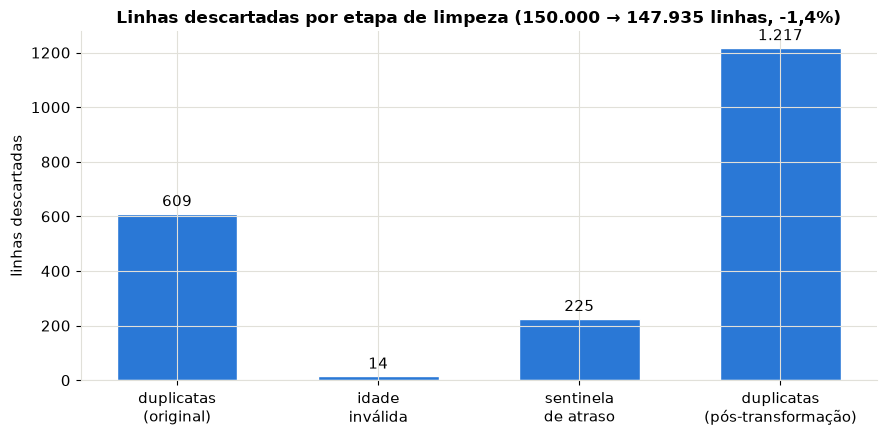

Confirmando: o dataset limpo passa no contrato —
  passou? True | violações: 0


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
passos = ["dropped_duplicates", "dropped_invalid_age", "dropped_sentinel_late",
          "dropped_duplicates_post"]
valores = [getattr(stats, p) for p in passos]
rotulos = ["duplicatas\n(original)", "idade\ninválida", "sentinela\nde atraso",
           "duplicatas\n(pós-transformação)"]

bars = ax.bar(rotulos, valores, color=BLUE, edgecolor="white", width=0.6)
ax.bar_label(bars, fmt=lambda v: f"{int(v):,}".replace(",", "."), padding=3)
# pt-BR: ponto como separador de milhar, vírgula como decimal — as duas
# trocas não podem ser feitas com um único .replace() ingênuo.
linhas_in = f"{stats.rows_in:,}".replace(",", ".")
linhas_out = f"{stats.rows_out:,}".replace(",", ".")
percentual = f"{stats.drop_rate * 100:.1f}".replace(".", ",")
ax.set_title(f"Linhas descartadas por etapa de limpeza "
             f"({linhas_in} \u2192 {linhas_out} linhas, -{percentual}%)")
ax.set_ylabel("linhas descartadas")
fig.tight_layout()
plt.show()

print("Confirmando: o dataset limpo passa no contrato —")
resultado_limpo = validate_batch(limpo, CreditReferenceSchema, "dataset_limpo")
print(f"  passou? {resultado_limpo.passed} | violações: {resultado_limpo.n_failures}")

<a id="3"></a>
## 3. O modelo baseline

Carrega o artefato treinado por `src/credit_scoring/train.py`
(`models/credit_model.joblib`) e revisita a escolha entre os dois candidatos.

In [9]:
bundle = load_model()
val = bundle["validation_metrics"]

print(f"Candidato vencedor: {bundle['candidate']}")
print(f"Limiar de decisão: {bundle['threshold']}")
print()
pd.Series(val, name="validação (fora da amostra)").to_frame().round(4)

Candidato vencedor: xgboost
Limiar de decisão: 0.5



,validação (fora da amostra)
roc_auc,0.8687
pr_auc,0.3890
ks_statistic,0.5920
brier,0.1364
precision,0.2242
recall,0.7686
f1,0.3471
default_rate,0.0666
approval_rate,0.7717
approved_bad_rate,0.0200


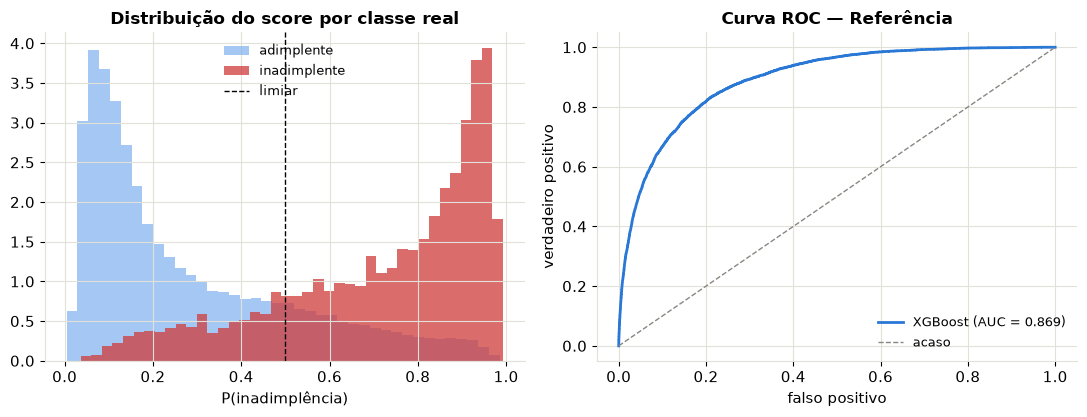

In [10]:
reference = pd.read_csv(settings.reference_path)
scores_ref = score(reference, bundle)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

# Distribuição do score por classe real — separação visual do modelo.
ax = axes[0]
for classe, cor, rotulo in [(0, BLUE_LIGHT, "adimplente"), (1, CRITICAL, "inadimplente")]:
    mask = reference[TARGET] == classe
    ax.hist(scores_ref[mask], bins=40, alpha=0.75, color=cor, label=rotulo, density=True)
ax.axvline(bundle["threshold"], color="black", linestyle="--", linewidth=1, label="limiar")
ax.set_title("Distribuição do score por classe real")
ax.set_xlabel("P(inadimplência)")
ax.legend(frameon=False, fontsize=9)

# Curva ROC manual, sem reimportar sklearn.metrics.RocCurveDisplay.
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(reference[TARGET], scores_ref)
ax = axes[1]
ax.plot(fpr, tpr, color=BLUE, linewidth=2, label=f"XGBoost (AUC = {val['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--", linewidth=1, label="acaso")
ax.set_title("Curva ROC — Referência")
ax.set_xlabel("falso positivo")
ax.set_ylabel("verdadeiro positivo")
ax.legend(frameon=False, fontsize=9)

fig.tight_layout()
plt.show()

<a id="4"></a>
## 4. Os cinco lotes de drift

Os cinco cenários mensais gerados por `src/drift/simulate.py`, do mês
estável à recessão. Para cada um: PSI por feature (`src/drift/statistics.py`)
e o desempenho do modelo nesse lote.

In [11]:
linhas_resumo = []
tabelas_psi = {}

for cenario in SCENARIOS:
    caminho = settings.production_dir / f"{cenario.name}.csv"
    lote = pd.read_csv(caminho)
    scores_lote = score(lote, bundle)
    metricas = compute_metrics(lote[TARGET].to_numpy(), scores_lote, bundle["threshold"])

    tabela = drift_table(reference, lote, FEATURES)
    resumo_drift = dataset_drift_summary(tabela)
    tabelas_psi[cenario.name] = tabela.set_index("feature")["psi"]

    linhas_resumo.append({
        "lote": cenario.name,
        "tipo": cenario.kind,
        "roc_auc": metricas.roc_auc,
        "delta_auc": metricas.roc_auc - val["roc_auc"],
        "default_rate": metricas.default_rate,
        "approved_bad_rate": metricas.approved_bad_rate,
        "max_psi": resumo_drift["max_psi"],
        "n_drifted": resumo_drift["n_drifted"],
    })

resumo_lotes = pd.DataFrame(linhas_resumo).set_index("lote")
resumo_lotes.round(4)

,tipo,roc_auc,delta_auc,default_rate,approved_bad_rate,max_psi,n_drifted
lote,,,,,,,
2024-01_estavel,nenhum,0.8711,0.0024,0.0635,0.0171,0.0017,0
2024-02_inflacao_leve,data,0.8619,-0.0068,0.0646,0.0197,0.0553,0
2024-03_inflacao_forte,data,0.8311,-0.0376,0.0629,0.0192,0.4672,2
2024-04_novo_perfil,data+covariavel,0.8254,-0.0432,0.0681,0.0179,0.5489,3
2024-05_recessao,concept,0.8233,-0.0454,0.1039,0.0448,0.0020,0


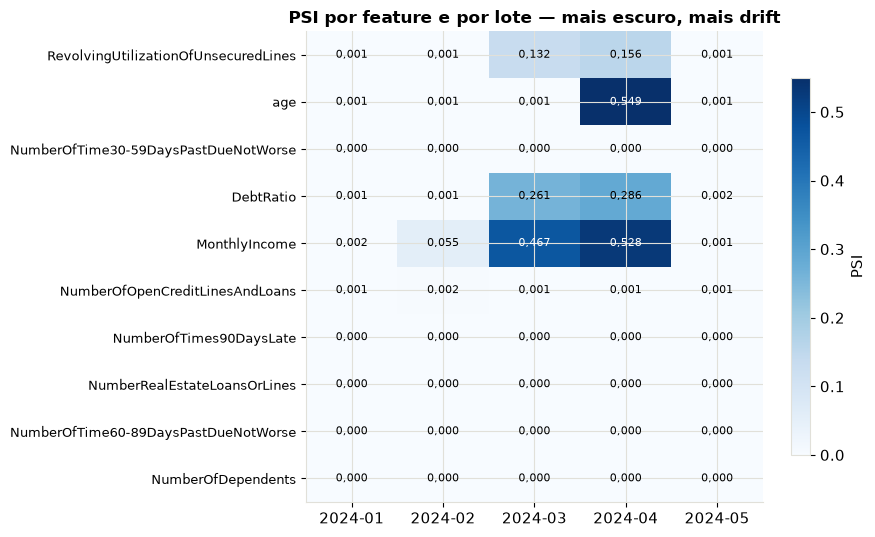

In [12]:
# Heatmap de PSI (feature x lote) em matplotlib puro.
matriz_psi = pd.DataFrame(tabelas_psi).loc[FEATURES]

fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(matriz_psi.values, cmap="Blues", aspect="auto", vmin=0, vmax=matriz_psi.values.max())

ax.set_xticks(range(len(matriz_psi.columns)))
ax.set_xticklabels([c.split("_", 1)[0] for c in matriz_psi.columns], rotation=0)
ax.set_yticks(range(len(matriz_psi.index)))
ax.set_yticklabels(matriz_psi.index, fontsize=9)

for i in range(matriz_psi.shape[0]):
    for j in range(matriz_psi.shape[1]):
        valor = matriz_psi.values[i, j]
        cor_texto = "white" if valor > matriz_psi.values.max() * 0.55 else "black"
        ax.text(j, i, f"{valor:.3f}".replace(".", ","), ha="center", va="center",
                fontsize=8, color=cor_texto)

ax.set_title("PSI por feature e por lote — mais escuro, mais drift")
fig.colorbar(im, ax=ax, label="PSI", shrink=0.8)
fig.tight_layout()
plt.show()

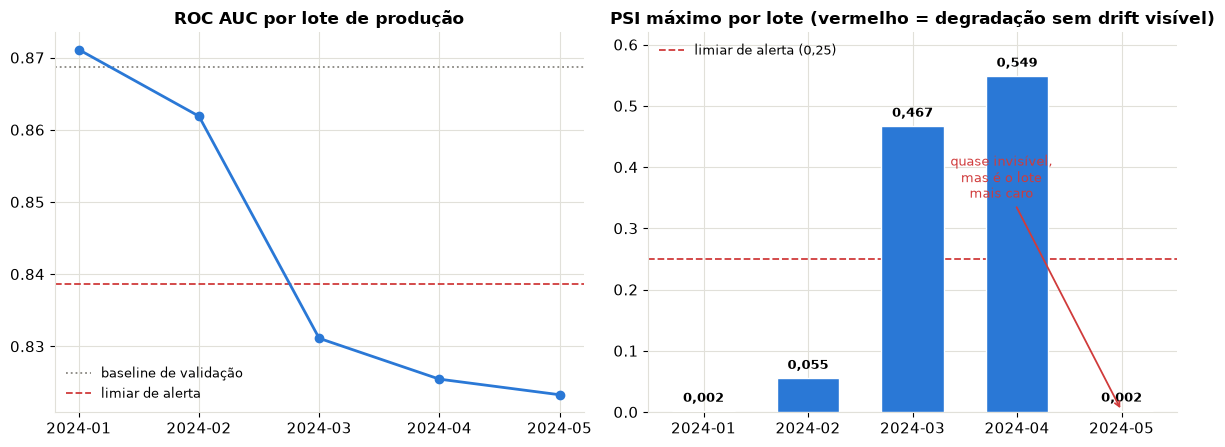

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

x = list(range(len(resumo_lotes)))
rotulos_x = [i.split("_", 1)[0] for i in resumo_lotes.index]

ax = axes[0]
ax.plot(x, resumo_lotes["roc_auc"], marker="o", color=BLUE, linewidth=2, zorder=3)
ax.axhline(val["roc_auc"], color=GRAY, linestyle=":", linewidth=1.3, label="baseline de validação")
ax.axhline(val["roc_auc"] - settings.auc_degradation_threshold, color=CRITICAL,
           linestyle="--", linewidth=1.3, label="limiar de alerta")
ax.set_xticks(x)
ax.set_xticklabels(rotulos_x)
ax.set_title("ROC AUC por lote de produção")
ax.legend(frameon=False, fontsize=9, loc="lower left")

# PSI máximo: a barra de 2024-05 é visualmente quase zero — esse "quase
# sumiço" É o achado, mas sem rótulo de valor pareceria um dado faltando.
# Por isso todo valor vai anotado em cima da barra, e o lote de recessão
# recebe uma seta explícita.
ax = axes[1]
cores = [CRITICAL if n == 0 and resumo_lotes["delta_auc"].iloc[i] <= -0.03 else BLUE
         for i, n in enumerate(resumo_lotes["n_drifted"])]
alturas = resumo_lotes["max_psi"].to_numpy()
bars = ax.bar(x, alturas, color=cores, edgecolor="white", width=0.6, zorder=3)
for xi, altura in zip(x, alturas):
    ax.text(xi, altura + 0.015, f"{altura:.3f}".replace(".", ","), ha="center",
            fontsize=9, fontweight="bold")
ax.axhline(settings.psi_alert_threshold, color=CRITICAL, linestyle="--", linewidth=1.3,
           label="limiar de alerta (0,25)")

idx_recessao = rotulos_x.index("2024-05")
ax.annotate(
    "quase invisível,\nmas é o lote\nmais caro",
    xy=(idx_recessao, alturas[idx_recessao]), xytext=(idx_recessao - 1.15, 0.35),
    fontsize=9, color=CRITICAL, ha="center",
    arrowprops={"arrowstyle": "->", "color": CRITICAL, "lw": 1.3},
)

ax.set_xticks(x)
ax.set_xticklabels(rotulos_x)
ax.set_ylim(0, 0.62)
ax.set_title("PSI máximo por lote (vermelho = degradação sem drift visível)")
ax.legend(frameon=False, fontsize=9, loc="upper left")

fig.tight_layout()
plt.show()

<a id="5"></a>
## 5. O achado: degradação silenciosa

Compare os dois últimos lotes da tabela da Seção 4: `2024-04_novo_perfil` e
`2024-05_recessao`. A queda de AUC é parecida — mas o PSI conta duas histórias
completamente diferentes.

In [14]:
comparacao_final = resumo_lotes.loc[["2024-04_novo_perfil", "2024-05_recessao"],
                                     ["tipo", "roc_auc", "delta_auc", "max_psi", "n_drifted", "approved_bad_rate"]]
comparacao_final.round(4)

,tipo,roc_auc,delta_auc,max_psi,n_drifted,approved_bad_rate
lote,,,,,,
2024-04_novo_perfil,data+covariavel,0.8254,-0.0432,0.5489,3,0.0179
2024-05_recessao,concept,0.8233,-0.0454,0.0020,0,0.0448


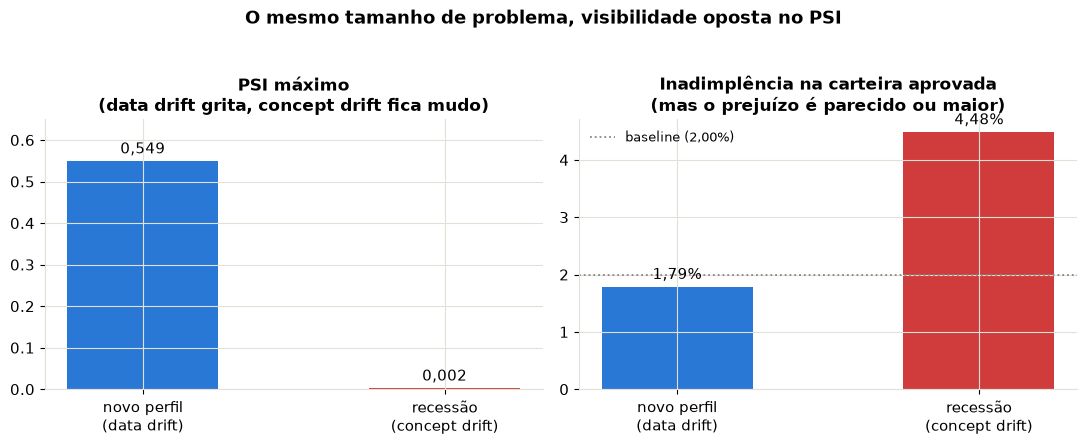

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

destaque = ["2024-04_novo_perfil", "2024-05_recessao"]
cores_destaque = [BLUE, CRITICAL]
rotulos_destaque = ["novo perfil\n(data drift)", "recessão\n(concept drift)"]

ax = axes[0]
bars = ax.bar(rotulos_destaque, resumo_lotes.loc[destaque, "max_psi"], color=cores_destaque, width=0.5)
ax.bar_label(bars, fmt=lambda v: f"{v:.3f}".replace(".", ","), padding=3)
ax.set_title("PSI máximo\n(data drift grita, concept drift fica mudo)")
ax.set_ylim(0, 0.65)

ax = axes[1]
valores_bad_rate = resumo_lotes.loc[destaque, "approved_bad_rate"] * 100
bars = ax.bar(rotulos_destaque, valores_bad_rate, color=cores_destaque, width=0.5)
ax.bar_label(bars, fmt=lambda v: f"{v:.2f}%".replace(".", ","), padding=3)
ax.axhline(val["approved_bad_rate"] * 100, color=GRAY, linestyle=":", linewidth=1.3,
           label=f"baseline ({val['approved_bad_rate']*100:.2f}%)".replace(".", ","))
ax.set_title("Inadimplência na carteira aprovada\n(mas o prejuízo é parecido ou maior)")
ax.legend(frameon=False, fontsize=9)

fig.suptitle("O mesmo tamanho de problema, visibilidade oposta no PSI", fontweight="bold", y=1.03)
fig.tight_layout()
plt.show()

**Leitura:** em `2024-04`, o PSI avisa — três features em drift, máximo de
0,549. Em `2024-05`, o PSI fica praticamente parado (0,002) e mesmo assim a
inadimplência na carteira aprovada é a maior de todos os lotes. É a
"degradação silenciosa" do enunciado: um monitor que só olhasse distribuição
de features não veria nada de errado no lote mais caro.

<a id="6"></a>
## 6. Atribuição causal

O experimento fatorial 2×2 de `src/drift/attribution.py` — rodado
separadamente via `make attribution` — isola quanto da degradação vem de cada
mecanismo. Lendo o laudo salvo em `reports/atribuicao_causal.json`:

In [16]:
caminho_atribuicao = settings.reports_dir / "atribuicao_causal.json"
atribuicao = json.loads(caminho_atribuicao.read_text(encoding="utf-8"))

condicoes = pd.DataFrame(atribuicao["conditions"]).set_index("name")
decomposicao = atribuicao["decomposition"]

condicoes[["roc_auc", "auc_delta", "default_rate", "approved_bad_rate", "max_psi", "n_drifted_features"]]

,roc_auc,auc_delta,default_rate,approved_bad_rate,max_psi,n_drifted_features
name,,,,,,
controle,0.8691,0.0005,0.0669,0.0194,0.0020,0
so_data_drift,0.8398,-0.0289,0.0669,0.0166,0.5613,3
so_concept_drift,0.8193,-0.0494,0.1047,0.0466,0.0020,0
ambos,0.7196,-0.1490,0.1746,0.1002,0.5613,3


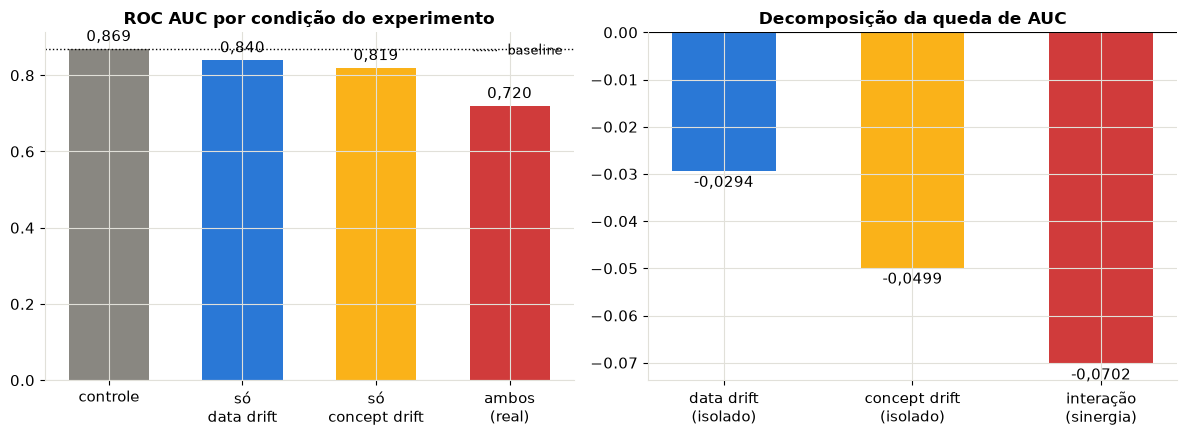

Share do dano isolado: data drift = 37,1%, concept drift = 62,9%


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ordem = ["controle", "so_data_drift", "so_concept_drift", "ambos"]
rotulos = ["controle", "só\ndata drift", "só\nconcept drift", "ambos\n(real)"]
cores = [GRAY, BLUE, WARNING, CRITICAL]

ax = axes[0]
bars = ax.bar(rotulos, condicoes.loc[ordem, "roc_auc"], color=cores, width=0.6)
ax.bar_label(bars, fmt=lambda v: f"{v:.3f}".replace(".", ","), padding=3)
ax.axhline(val["roc_auc"], color="black", linestyle=":", linewidth=1, label="baseline")
ax.set_title("ROC AUC por condição do experimento")
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
partes = ["efeito_data_drift", "efeito_concept_drift", "interacao"]
rotulos_partes = ["data drift\n(isolado)", "concept drift\n(isolado)", "interação\n(sinergia)"]
valores_partes = [decomposicao[p] for p in partes]
cores_partes = [BLUE, WARNING, CRITICAL]
bars = ax.bar(rotulos_partes, valores_partes, color=cores_partes, width=0.55)
ax.bar_label(bars, fmt=lambda v: f"{v:+.4f}".replace(".", ","), padding=3)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Decomposição da queda de AUC")

fig.tight_layout()
plt.show()

share_data_fmt = f"{decomposicao['share_data_drift'] * 100:.1f}".replace(".", ",")
share_concept_fmt = f"{decomposicao['share_concept_drift'] * 100:.1f}".replace(".", ",")
print(f"Share do dano isolado: data drift = {share_data_fmt}%, concept drift = {share_concept_fmt}%")

O concept drift, sozinho, responde pela maior fatia do dano — e é justamente
o mecanismo que o PSI não enxerga. A interação entre os dois é maior que
qualquer efeito isolado: quando a base já está fora do domínio de treino
(data drift), o modelo fica ainda mais vulnerável a uma mudança de relação
(concept drift). Discussão completa em
[`docs/causal_analysis.md`](../docs/causal_analysis.md).

<a id="7"></a>
## 7. Conclusões

1. **O contrato de dados não é arbitrário** — cada regra nasceu de um defeito
   real e visível no dataset bruto (Seção 1), e a transformação que leva o
   bruto ao contrato é auditável passo a passo (Seção 2).
2. **O modelo baseline discrimina bem** na Referência (ROC AUC ≈ 0,87), o
   suficiente para que a degradação simulada seja mensurável.
3. **PSI detecta data drift de forma confiável** — os lotes de inflação e
   novo perfil disparam o alerta exatamente como esperado.
4. **PSI é cego para concept drift** — o lote de recessão prova isso de forma
   isolada: AUC cai, inadimplência sobe, e o PSI praticamente não se move.
5. **O experimento causal quantifica o ponto cego**: a maior parte do dano
   isolado vem do mecanismo que o monitoramento de distribuição não vê, e os
   dois mecanismos se reforçam quando ocorrem juntos — o cenário realista de
   uma recessão.

Isso é o que sustenta a arquitetura do projeto: **drift de dados e
desempenho do modelo precisam ser monitorados juntos** — ver
`src/drift/detect.py::DriftReport.alerts()` e o alerta
`degradacao_silenciosa`, que só existe porque as duas fontes são cruzadas.